In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

In [2]:
customers = pd.read_csv(r"D:\Customer Segmentation Analysis\data\processed\customers_cleaned.csv")
transactions = pd.read_csv(r"D:\Customer Segmentation Analysis\data\processed\transactions_cleaned.csv")
products = pd.read_csv(r"D:\Customer Segmentation Analysis\data\processed\products_cleaned.csv")

# Convert dates
customers["SignupDate"] = pd.to_datetime(customers["SignupDate"])
transactions["OrderDate"] = pd.to_datetime(transactions["OrderDate"])

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [3]:
# customer purchase frequency

purchase_frequency = transactions.groupby(
    "CustomerID"
)["TransactionID"].count()
print(purchase_frequency.head(10))

CustomerID
C00001     4
C00002     5
C00003     2
C00004     5
C00005     3
C00006     1
C00007     6
C00008     7
C00009     2
C00010    11
Name: TransactionID, dtype: int64


In [4]:
# average purchase frequency

average_frequency = purchase_frequency.mean()
print("Average Purchase Frequency: ", round(average_frequency, 2))

Average Purchase Frequency:  5.22


In [5]:
# customer spending

customer_spending = transactions.groupby(
    "CustomerID"
)["Sales"].sum()
print(customer_spending.head(10))

CustomerID
C00001    1708.39
C00002    1121.89
C00003     761.39
C00004    1362.58
C00005    1472.60
C00006      61.45
C00007    2086.28
C00008    2550.72
C00009     399.96
C00010    4116.41
Name: Sales, dtype: float64


In [7]:
# avg customer spending

average_spending = customer_spending.mean()
print("Average Customer Spending: ", round(average_spending, 2))

Average Customer Spending:  1503.6


In [12]:
# customer summary

customer_summary = transactions.groupby("CustomerID").agg(
    TotalTransactions = ("TransactionID", "nunique"),
    TotalSpending = ("Sales", "sum"),
    TotalProfit = ("Profit", "sum"),
    TotalQuantity = ("Quantity", "sum"),
    FirstPurchase = ("OrderDate", "min"),
    LastPurchase = ("OrderDate", "max")
).reset_index()

# Add customer information

customer_summary = customer_summary.merge(
    customers[["CustomerID", "Region", "Country", "AcquisitionChannel"]],
    on = "CustomerID",
    how = "left"
)

customer_summary.head()

,CustomerID,TotalTransactions,TotalSpending,TotalProfit,TotalQuantity,FirstPurchase,LastPurchase,Region,Country,AcquisitionChannel
0,C00001,4,1708.39,598.02,16,2024-09-20,2024-09-20,South,Nepal,In-Store
1,C00002,5,1121.89,268.94,13,2021-11-08,2024-05-10,West,Nepal,Mobile App
2,C00003,2,761.39,238.15,7,2022-07-15,2025-10-17,East,Bangladesh,Website
3,C00004,5,1362.58,489.05,13,2022-09-17,2025-10-13,North,Nepal,In-Store
4,C00005,3,1472.60,377.63,11,2022-10-07,2025-02-10,Central,India,Website


In [13]:
# top 10 customers by spending

top_customers = customer_summary.sort_values(
    by = "TotalSpending",
    ascending = False
).head(10)

print(top_customers[[
    "CustomerID",
    "TotalTransactions",
    "TotalSpending",
    "TotalProfit"
]])

     CustomerID  TotalTransactions  TotalSpending  TotalProfit
373      C00397                 19        7193.04      2555.01
1133     C01187                 21        7078.08      2340.81
4098     C04275                 18        6578.73      2407.01
1806     C01890                 19        6350.68      2425.68
3419     C03577                 17        6290.40      2262.77
4411     C04607                 13        6052.27      2203.14
2774     C02904                 18        5780.49      2319.53
4385     C04580                 16        5775.60      2311.68
701      C00741                 19        5693.63      1975.37
171      C00181                 12        5651.98      2127.05


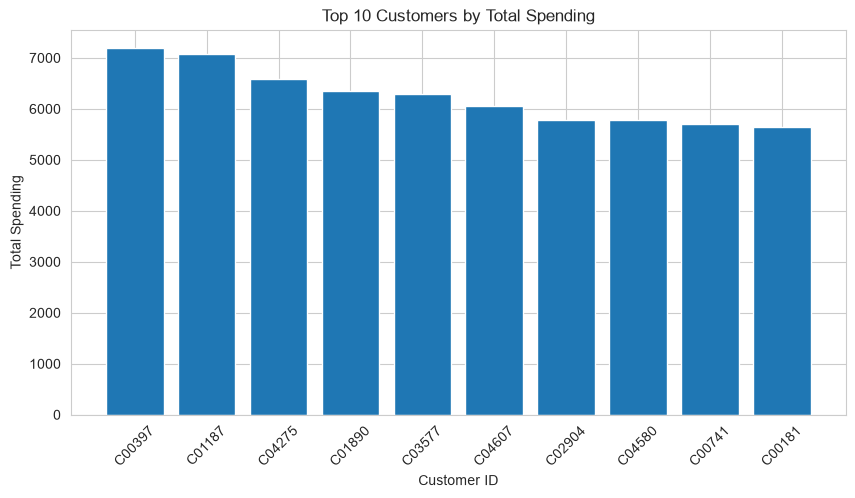

In [14]:
# visualization of top 10 customers by spending

plt.figure(figsize=(10, 5))

plt.bar(
    top_customers["CustomerID"].astype(str),
    top_customers["TotalSpending"]
)

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)

plt.show()

In [15]:
# purchase frequency distribution

frequency_distribution = purchase_frequency.value_counts().sort_index()

print(frequency_distribution)

TransactionID
1     612
2     912
3     857
4     726
5     676
6     588
7     443
8     369
9     270
10    257
11    171
12    131
13     87
14     49
15     41
16     23
17      4
18      5
19      5
20      4
21      2
Name: count, dtype: int64


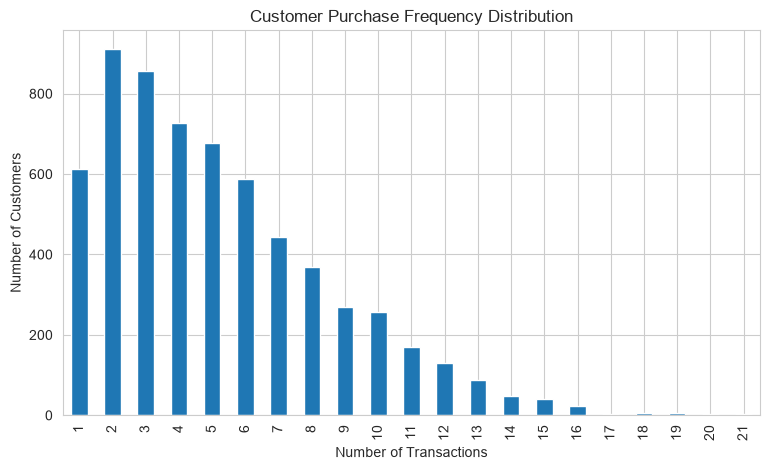

In [16]:
# visualization of purchase frequency distribution
plt.figure(figsize=(9, 5))

frequency_distribution.plot(kind="bar")

plt.title("Customer Purchase Frequency Distribution")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")

plt.show()

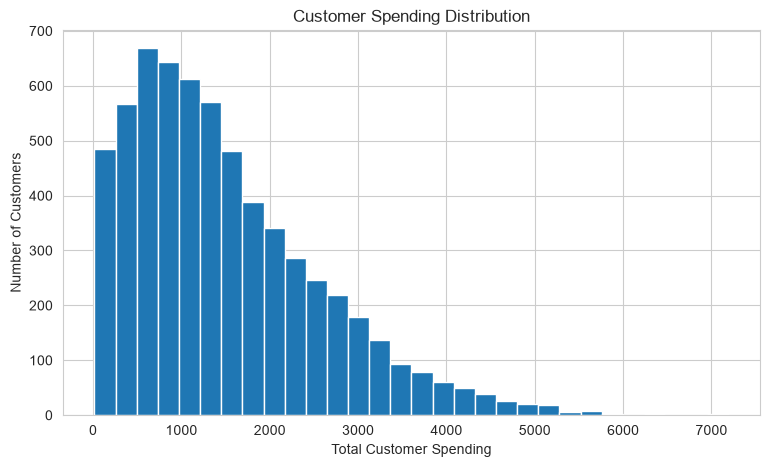

In [17]:
# visualization of customer spending distribution

plt.figure(figsize=(9, 5))

plt.hist(customer_spending, bins=30)

plt.title("Customer Spending Distribution")
plt.xlabel("Total Customer Spending")
plt.ylabel("Number of Customers")

plt.show()

In [18]:
# saving
customer_summary.to_csv(
    r"D:\Customer Segmentation Analysis\data\processed\customer_summary.csv",
    index=False
)

print("Customer summary saved.")

Customer summary saved.
